# EDA do treino: frequência de sinistros por apólice

**O problema.** Quantos sinistros são esperados para diferentes perfis de veículo, condutor e região, considerando o tempo de cobertura? Essa pergunta é estudada com registros de uma carteira francesa de seguros de automóveis (Dutang & Charpentier, 2018).

**Por que importa.** Cada apólice coberta por um ano contribui com uma apólice-ano de exposição. Dois sinistros observados em 20 apólices-ano correspondem a 10 por 100 apólices-ano. Se os mesmos dois sinistros forem observados em 100 apólices-ano, a taxa será de 2 por 100. Assim, grupos com tempos de cobertura diferentes podem ser comparados na mesma escala. Mesmo quando a taxa prevista para a carteira está próxima da observada, as taxas de alguns segmentos podem ser subestimadas ou superestimadas.

**O papel deste notebook.** Na partição de **treino**, são examinadas as contagens de sinistros (`ClaimNb`), a duração da cobertura (`Exposure`) e as taxas observadas por perfil e faixa de exposição. Cada taxa é calculada como `100 × Σ ClaimNb / Σ Exposure`. Essa análise prepara a comparação posterior entre as taxas observadas e previstas por segmento.

In [1]:
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("retina")
import pandas as pd
from IPython.display import display

from freq_sinistros import artifacts, eda, plots
from freq_sinistros.data import load_partitions

LANG = "pt_br"
ROOT = artifacts.project_root()
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 20

## 1. Origem, unidade e partição

**Pergunta.** Qual arquivo, qual unidade de observação e qual partição sustentam esta análise?

In [2]:
parts, provenance = load_partitions(ROOT, keep=("train",))
train = parts["train"]
display(artifacts.provenance_table(provenance, len(train), LANG))

,item,value
0,SHA-256 do ARFF,a45363e056e2ea56408b38eeb9d4d04d7f6c6982eb7a14...
1,SHA-256 das atribuições,f14f53509d63ff468f025fd43096a5c2d12ba3fdd48529...
2,regra de partição,bucket = int.from_bytes(sha256(utf8('freMTPL2f...
3,partição usada,train
4,registros de treino,"474,581"
5,unidade de observação,registro de cobertura (IDpol)


### Insights

Foi usado o arquivo bruto do OpenML 41214, versão 1 (`freMTPL2freq`), conferido por SHA-256 contra o manifesto de aquisição. A auditoria confirmou 678.013 valores distintos de `IDpol` e nenhum valor faltante. Cada linha representa um registro de cobertura, com duração medida em anos (Dutang & Charpentier, 2018).

Na etapa 2 do projeto, os registros foram divididos em aproximadamente **70% para treino, 15% para validação e 15% para teste**. A atribuição foi feita de forma determinística pelo hash SHA-256 de `IDpol`, independentemente da ordem das linhas. Foi verificado que cada identificador aparece em uma única partição e que todos foram atribuídos.

| Partição | Registros | Uso |
| --- | ---: | --- |
| Treino | 474.581 | EDA, pré-processamento e ajuste dos modelos |
| Validação | 101.573 | Comparação e escolha do modelo |
| Teste | 101.859 | Uma única avaliação após o congelamento do modelo |

**Por que a EDA foi feita depois da partição?** A auditoria de integridade foi realizada antes da divisão. A partição foi definida antes da EDA para que a exploração, a comparação de modelos e a avaliação final fossem conduzidas em conjuntos distintos (Wickham & Grolemund, 2017). A relação entre exposição e frequência de sinistros, por exemplo, foi explorada no treino. O teste foi reservado até o congelamento do modelo para evitar que seus resultados influenciassem decisões de modelagem e levassem a sobreajuste à própria amostra de teste (Dwork et al., 2015).

O leitor interpreta o ARFF integral em memória. Para a EDA deste notebook, são disponibilizadas apenas as linhas de treino.

## 2. Dicionário das variáveis

**Pergunta.** Quais são as 12 variáveis do `freMTPL2freq`, e como são diferenciados o alvo, a exposição, o identificador e as covariáveis?

In [3]:
display(artifacts.variable_dictionary_table(train.columns, LANG))

,variável,papel / significado,unidade / categorias,disponibilidade
0,IDpol,identificador do registro de apolice,inteiro (rastreabilidade),disponivel; nao e preditor
1,ClaimNb,alvo: numero de sinistros no periodo de exposicao,contagem inteira >= 0,desfecho; indisponivel na estimacao da taxa
2,Exposure,exposicao (offset log) e dado do cenario de pr...,anos de cobertura,disponivel como duracao do cenario
3,Area,covariavel territorial (densidade ordinal),categoria A (rural) a F (centro urbano),hipotese: disponivel no cenario; a fonte descr...
4,VehPower,covariavel do veiculo: potência do veículo,valores ordenados (sem unidade publicada),hipotese: disponivel no cenario; a fonte descr...
5,VehAge,covariavel do veiculo: idade do veículo,anos,hipotese: disponivel no cenario; a fonte descr...
6,DrivAge,covariavel do condutor: idade do condutor,anos,hipotese: disponivel no cenario; a fonte descr...
7,BonusMalus,covariavel do condutor (historico de sinistros),"indice 50-350; <100 bonus, >100 malus",INDETERMINADA: instante de medicao nao documen...
8,VehBrand,covariavel do veiculo: grupo anonimizado da ma...,"11 categorias B1-B6, B10-B14 (significado nao ...",hipotese: disponivel no cenario; a fonte descr...
9,VehGas,covariavel do veiculo: tipo de combustível do ...,categoria Diesel ou Regular,hipotese: disponivel no cenario; a fonte descr...


### Insights

Foi apresentado o dicionário das 12 variáveis na ordem do conjunto de dados. `ClaimNb` foi identificado como o alvo de contagem, `Exposure` como a exposição em anos usada no offset, e `IDpol` como identificador destinado à rastreabilidade, não à predição. As nove variáveis restantes foram classificadas como covariáveis do veículo, do condutor ou territoriais. A disponibilidade das covariáveis na estimação foi tratada como hipótese porque a fonte não informa a data de referência; para `BonusMalus`, o instante de medição permanece indeterminado e a variável não integra a especificação principal.

## 3. Cálculo da EDA

**Pergunta.** Quais tabelas descritivas são obtidas do treino? A execução abaixo calcula todas elas de uma vez, incluindo a verificação das exposições curtas, o diagnóstico do offset e a cobertura de categorias.

In [4]:
tables, summary = eda.compute_eda(train)
sorted(tables)

['eda_claimnb_distribution',
 'eda_exposure_bands',
 'eda_exposure_histogram',
 'eda_rate_area',
 'eda_rate_driver_age',
 'eda_rate_region',
 'eda_rate_vehicle_age',
 'eda_short_exposure_bands',
 'eda_short_exposure_strata']

### Insights

Foram geradas nove tabelas e um resumo, todos derivados apenas das 474.581 linhas de treino (251.070,30 apólices-ano e 25.319 sinistros; taxa de 10,08 por 100 apólices-ano).

## 4. Distribuição de `ClaimNb`

**Pergunta.** Qual é a proporção de zeros e quão pesada é a cauda da contagem?

,claimnb,registros,share_of_valid_rows,sinistros,share_of_claims
0,0,450731,0.9497,0,0.0000
1,1,22512,0.0474,22512,0.8891
2,2,1259,0.0027,2518,0.0995
3,3,66,0.0001,198,0.0078
4,4,5,0.0000,20,0.0008
5,5,2,0.0000,10,0.0004
6,6,1,0.0000,6,0.0002
7,8,1,0.0000,8,0.0003
8,9,1,0.0000,9,0.0004
9,11,2,0.0000,22,0.0009


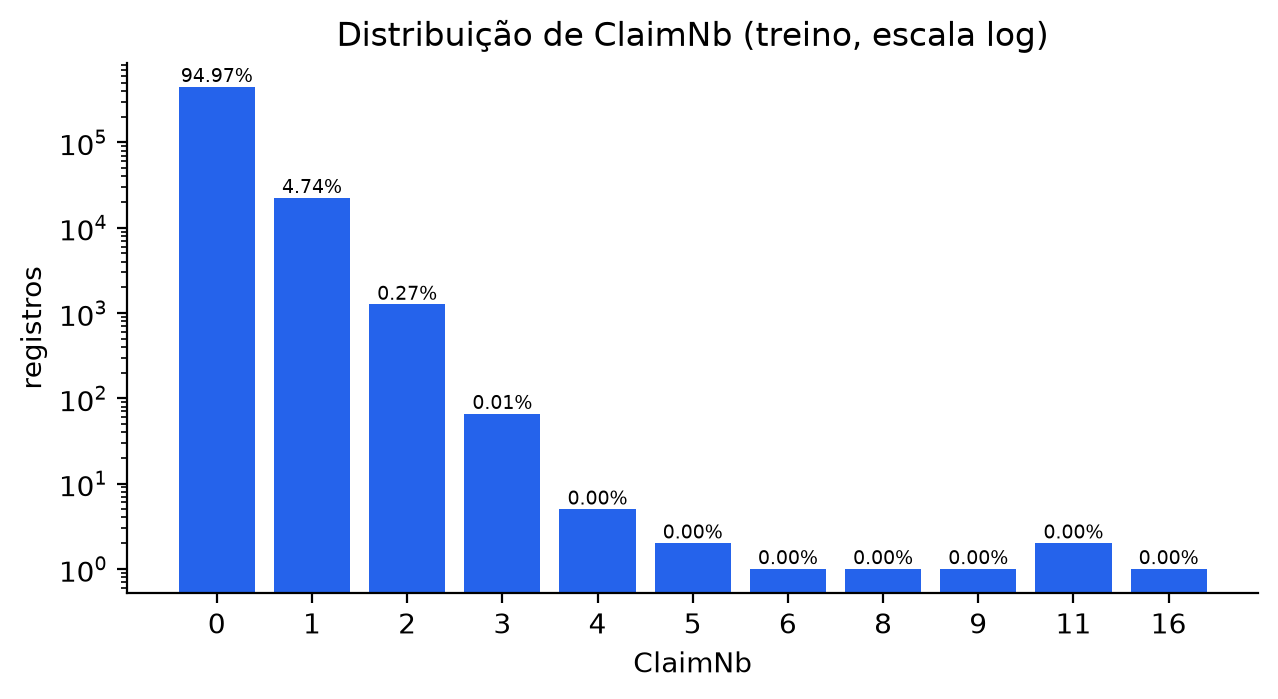

,item,value
0,registros com ClaimNb > 4,8.0000
1,sinistros nesses registros,71.0000
2,registros com Exposure > 1,869.0000
3,"registros com Exposure ≤ 0,02","13,465.0000"
4,registros com DrivAge = 100,3.0000
5,registros com VehAge = 100,11.0000


In [5]:
display(artifacts.localize(tables["eda_claimnb_distribution"], LANG))
plots.show(plots.plot_claimnb(tables["eda_claimnb_distribution"], LANG))
display(artifacts.extremes_table(summary, LANG))

### Insights

Zeros correspondem a 94,97% dos registros. Apólices com um sinistro respondem por 88,9% dos sinistros e com dois, por 9,9%. A cauda acima de quatro é rara: 8 registros somam 71 sinistros. Esses casos são válidos e foram preservados; sua concentração em poucos perfis é tratada na sensibilidade por perfil da comparação de modelos.

## 5. Distribuição de `Exposure`

**Pergunta.** Como a duração da cobertura se distribui, e quanto pesam as exposições muito curtas, exatamente um ano e acima de um ano?

,faixa,registros,rows_claim_valid,claims_claim_valid,exposure_valid,rows_rate_subset,exposure_rate_subset,claims_rate_subset,zeros_rate_subset,proporção de zeros,rate_per_100_policy_years
0,"(0, 0.02]",13465,13465,376.0000,150.0536,13465,150.0536,376.0000,13106,0.9733,250.5772
1,"(0.02, 0.08]",66879,66879,"1,583.0000","4,269.4100",66879,"4,269.4100","1,583.0000",65388,0.9777,37.0777
2,"(0.08, 0.25]",75529,75529,"3,046.0000","13,042.8100",75529,"13,042.8100","3,046.0000",72655,0.9619,23.3539
3,"(0.25, 0.50]",91750,91750,"4,515.0000","35,885.0100",91750,"35,885.0100","4,515.0000",87534,0.9540,12.5819
4,"(0.50, 0.75]",64735,64735,"4,140.0000","40,998.6700",64735,"40,998.6700","4,140.0000",60842,0.9399,10.0979
5,"(0.75, 1)",43493,43493,"3,294.0000","37,895.4600",43493,"37,895.4600","3,294.0000",40429,0.9296,8.6923
6,= 1,117861,117861,"8,336.0000","117,861.0000",117861,"117,861.0000","8,336.0000",109937,0.9328,7.0727
7,> 1,869,869,29.0000,967.8900,869,967.8900,29.0000,840,0.9666,2.9962
8,exposicao_invalida,0,0,0.0000,0.0000,0,0.0000,0.0000,0,NaN,NaN
9,total,474581,474581,"25,319.0000","251,070.3036",474581,"251,070.3036","25,319.0000",450731,0.9497,10.0844


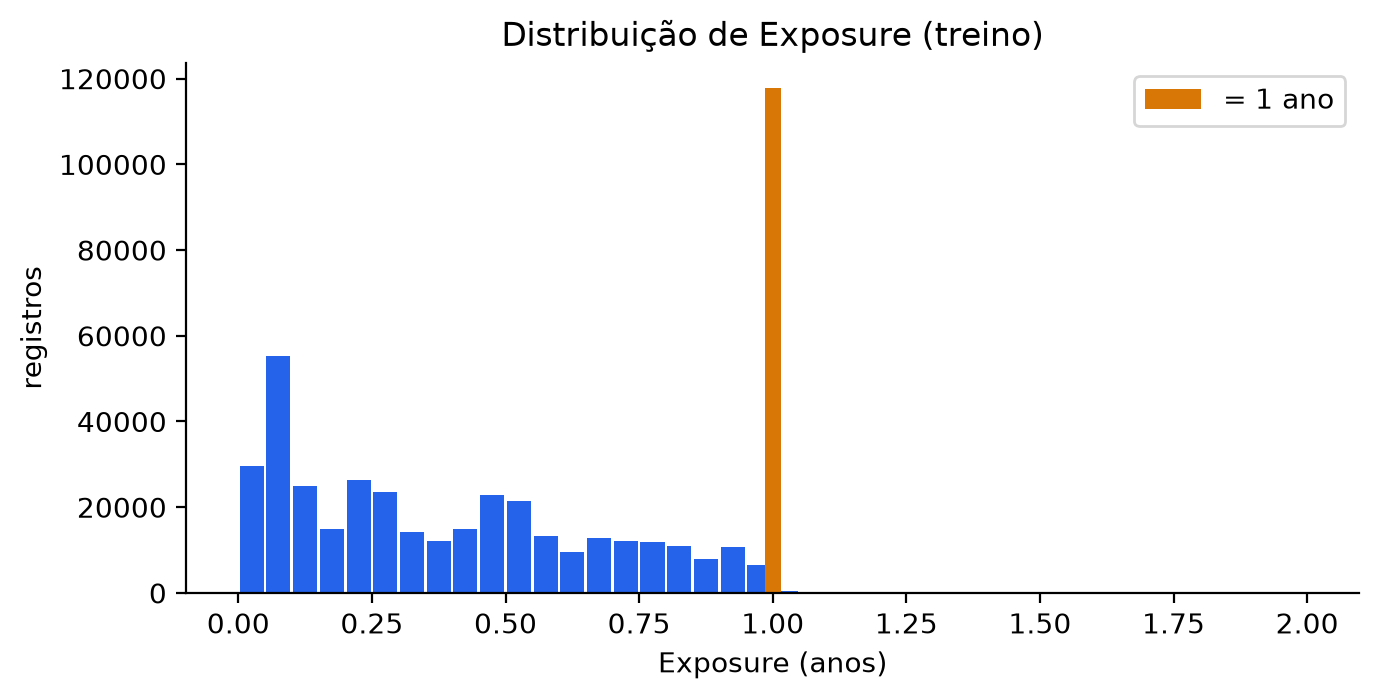

In [6]:
display(artifacts.localize(tables["eda_exposure_bands"], LANG))
plots.show(plots.plot_exposure(tables["eda_exposure_histogram"], LANG))

### Insights

Exposições de exatamente um ano são 24,8% dos registros e 46,9% da exposição total. A faixa `(0; 0,02]` (cerca de uma semana) tem 13.465 registros e a faixa acima de um ano, 869. A unidade é anos, conforme o dicionário (Dutang & Charpentier, 2018). Exposições acima de um ano são tratadas como cauda observada, não como erro, pois a fonte descreve as apólices como observadas predominantemente por um ano.

## 6. Frequência por faixa de exposição, idade e região

**Pergunta.** Como a taxa por 100 apólices-ano varia por faixa de exposição, idade do veículo, idade do condutor e região? Segmentos com menos de 500 registros ou menos de 25 apólices-ano são sinalizados como de baixo suporte.

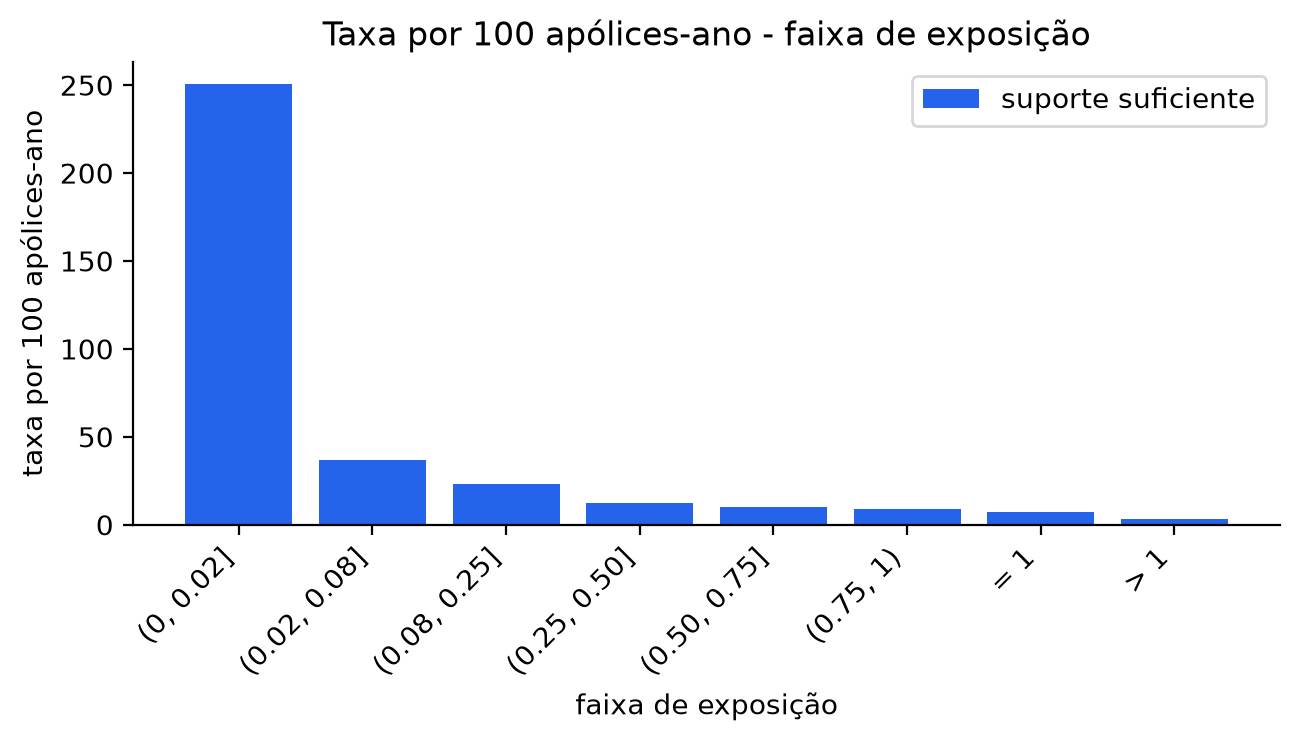

,segmento,registros,exposição,sinistros,zeros,proporção de zeros,taxa por 100 ap.-ano,baixo suporte
0,0-1,90374,"34,638.7546","5,715.0000",84996,0.9405,16.4989,False
1,2-5,134134,"71,307.9284","6,661.0000",127872,0.9533,9.3412,False
2,6-10,120059,"69,272.8475","6,855.0000",113602,0.9462,9.8957,False
3,11-20,124244,"72,285.4168","5,882.0000",118680,0.9552,8.1372,False
4,21+,5770,"3,565.3563",206.0000,5581,0.9672,5.7778,False


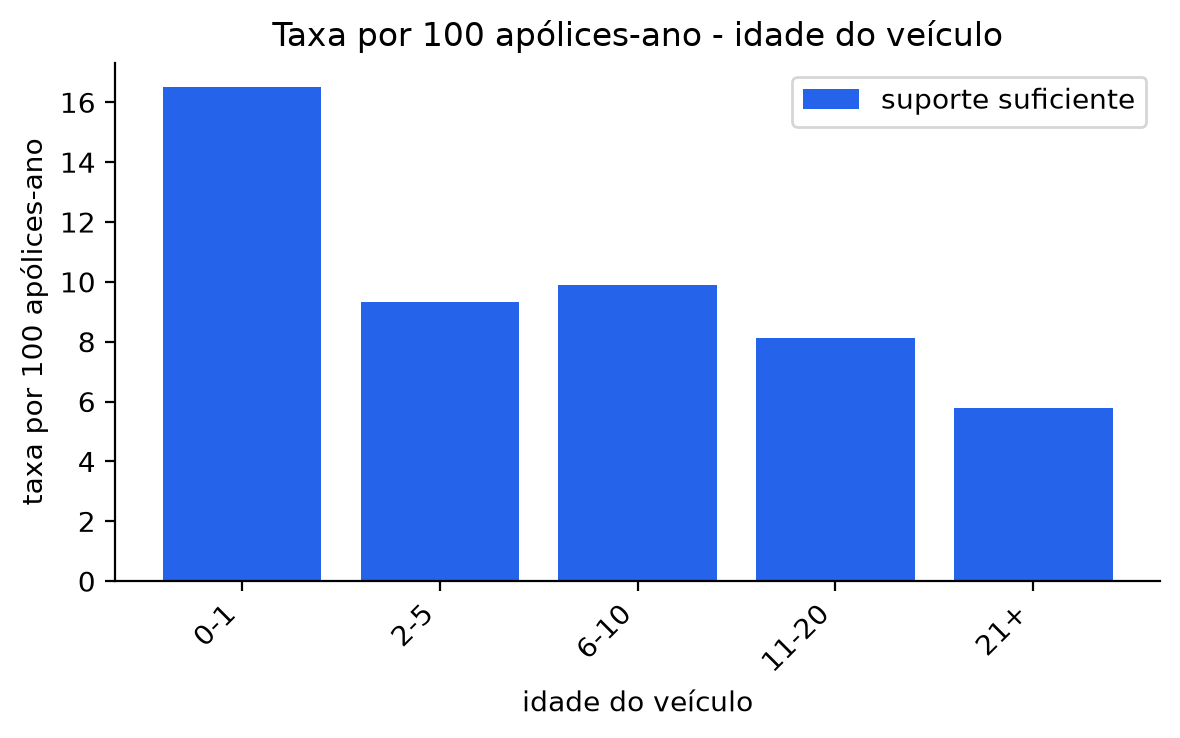

,segmento,registros,exposição,sinistros,zeros,proporção de zeros,taxa por 100 ap.-ano,baixo suporte
0,18-24,21187,"8,824.2567","1,668.0000",19656,0.9277,18.9024,False
1,25-34,98655,"45,279.8467","4,491.0000",94423,0.9571,9.9183,False
2,35-44,119593,"61,141.1634","5,670.0000",114220,0.9551,9.2736,False
3,45-54,114613,"62,874.4777","6,714.0000",108286,0.9448,10.6784,False
4,55-64,69283,"39,302.6415","3,559.0000",65914,0.9514,9.0554,False
5,65-74,35558,"22,524.8696","2,112.0000",33568,0.9440,9.3763,False
6,75+,15692,"11,123.0480","1,105.0000",14664,0.9345,9.9343,False


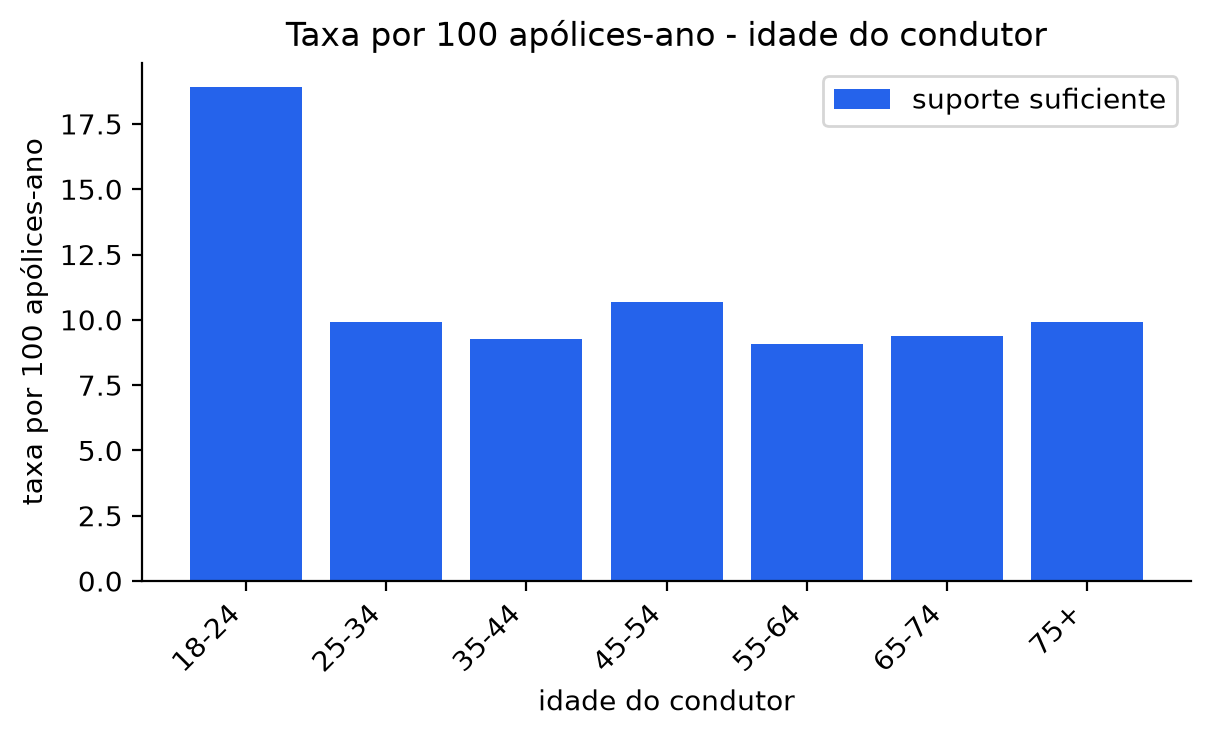

,segmento,registros,exposição,sinistros,zeros,proporção de zeros,taxa por 100 ap.-ano,baixo suporte
0,R11,48970,"21,209.7699","2,784.0000",46384,0.9472,13.1260,False
1,R21,2121,852.0368,120.0000,2010,0.9477,14.0839,False
2,R22,5606,"2,480.5850",297.0000,5320,0.9490,11.9730,False
3,R23,6196,"2,222.4600",212.0000,5999,0.9682,9.5390,False
4,R24,112569,"72,092.1193","6,420.0000",106422,0.9454,8.9053,False
5,R25,7655,"4,707.0442",448.0000,7227,0.9441,9.5177,False
6,R26,7364,"3,525.4488",345.0000,7030,0.9546,9.7860,False
7,R31,19062,"8,023.6161",825.0000,18298,0.9599,10.2821,False
8,R41,9013,"5,625.4010",404.0000,8624,0.9568,7.1817,False
9,R42,1573,866.3412,99.0000,1482,0.9421,11.4274,False


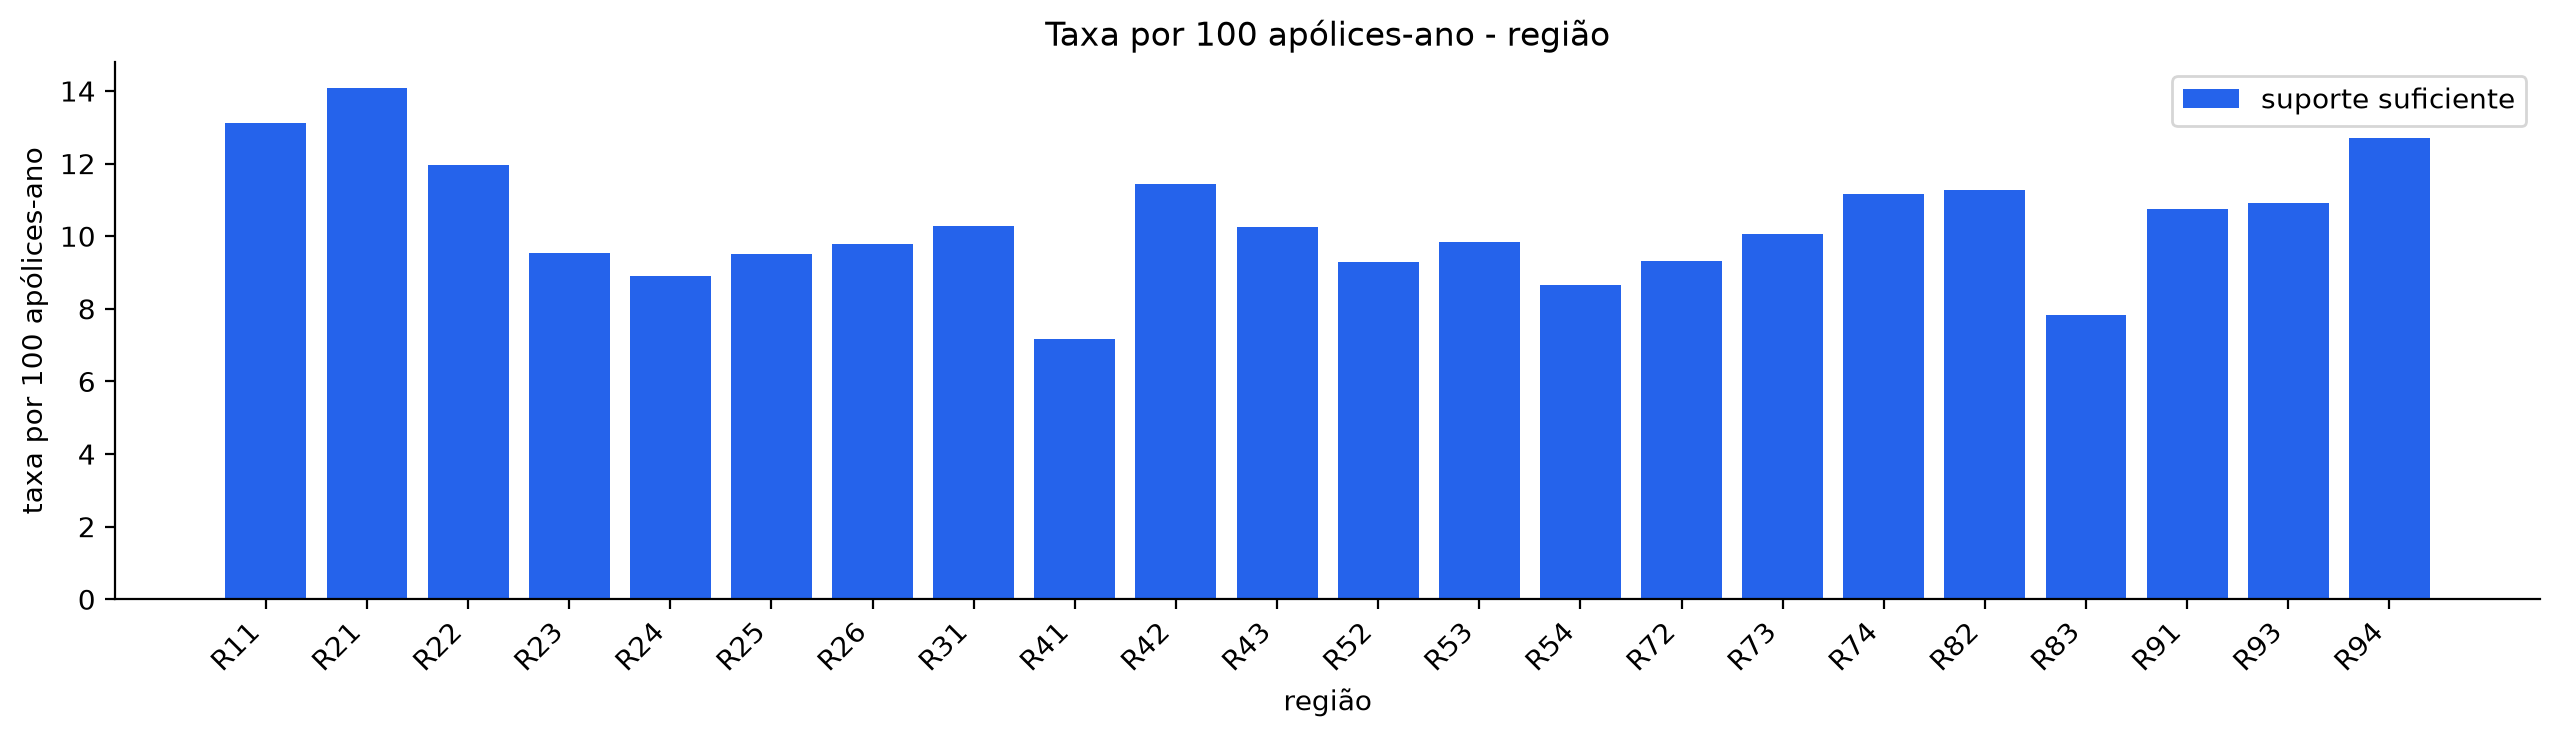

In [7]:
bands = eda.band_rate_table(tables["eda_exposure_bands"])
plots.show(plots.plot_rates(bands, LANG, "band"))
for name, key in (("age_veh", "eda_rate_vehicle_age"),
                  ("age_drv", "eda_rate_driver_age"),
                  ("region", "eda_rate_region")):
    table = tables[key]
    display(artifacts.localize(table, LANG))
    plots.show(plots.plot_rates(table, LANG, name))

### Insights

A taxa decresce com a duração da cobertura: 250,6 por 100 apólices-ano em `(0; 0,02]`, 7,07 em exatamente um ano e 3,00 acima de um ano. Por idade do veículo, a taxa é 16,5 em 0–1 ano e 8,1 em 11–20 anos; por idade do condutor, 18,9 em 18–24 e 9,3 em 35–44. Entre as regiões com suporte, as taxas vão de R41 (7,2) a R21 (14,1). Nenhum segmento do treino é de baixo suporte nas faixas de exposição e de idade; as regiões de baixo suporte, quando existem, aparecem hachuradas. Todas as diferenças são marginais e descritivas.

## 7. As exposições curtas persistem dentro de perfis?

**Pergunta.** A taxa elevada das exposições curtas decorre da composição por idade ou persiste dentro de estratos com suporte? A taxa de referência de cada estrato (idade do condutor × idade do veículo) usa as linhas com `Exposure ≥ 0,75`.

,faixa,registros,exposição,observed,expected_ref_rate,ratio_observed_expected,baixo suporte
0,"(0, 0.02]",13268,147.4625,371.0000,11.9991,30.9189,False
1,"(0.02, 0.08]",66078,"4,221.5300","1,557.0000",325.1986,4.7878,False
2,"(0.08, 0.25]",74545,"12,881.0000","2,974.0000","1,013.5496",2.9342,False
3,"(0.25, 0.50]",90872,"35,548.5300","4,457.0000","2,776.4421",1.6053,False
4,"(0.50, 0.75]",64104,"40,599.6800","4,088.0000","3,216.9969",1.2708,False
5,"(0.75, 1)",43151,"37,598.1400","3,267.0000","2,934.2332",1.1134,False
6,= 1,117004,"117,004.0000","8,282.0000","8,656.3169",0.9568,False
7,> 1,864,962.6500,29.0000,70.6776,0.4103,False


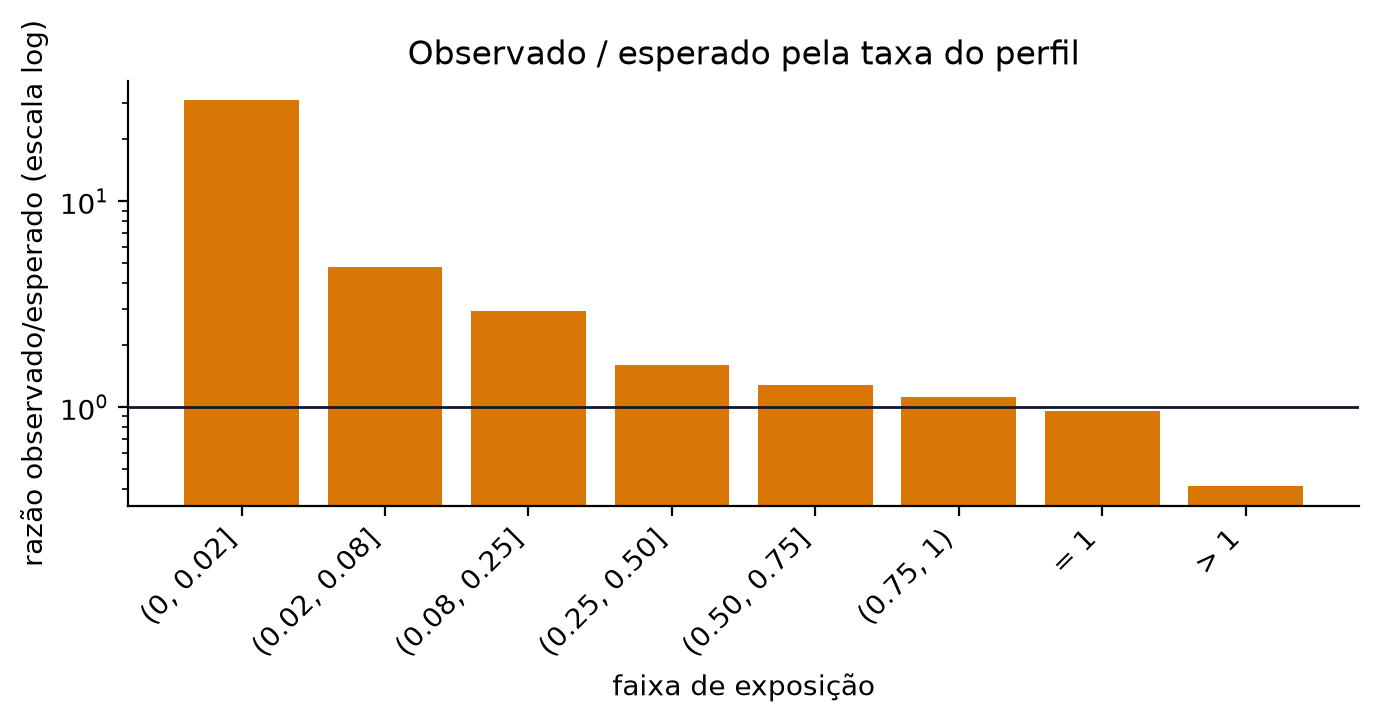

strata_total                           35.0000
strata_with_reference_support          30.0000
short_limit_exposure_le                 0.0800
reference_exposure_ge                   0.7500
strata_supported_in_both               24.0000
strata_short_rate_above_reference      24.0000
median_ratio_short_over_ref             4.1969
min_ratio_short_over_ref                2.7133
pooled_short_ratio_observed_expected    5.7177
dtype: float64

sample_rows                 100000
converged                     True
coefficient_log_exposure    0.3926
naive_se                    0.0164
approx_95_low               0.3605
approx_95_high              0.4247
assumed_by_offset           1.0000
dtype: object

In [8]:
display(artifacts.localize(tables["eda_short_exposure_bands"], LANG))
plots.show(plots.plot_short_check(tables["eda_short_exposure_bands"], LANG))
display(pd.Series(summary["short_exposure_check"]))
display(pd.Series(summary["offset_check"]))

### Insights

Em 24 de 24 estratos com suporte nos dois grupos, a taxa das linhas com `Exposure ≤ 0,08` supera a de referência (razão mediana 4,2; mínima 2,7). A razão observado/esperado é 30,9 em `(0; 0,02]`, 4,8 em `(0,02; 0,08]` e 0,96 em exatamente um ano. Assim, o padrão persiste dentro dos estratos de idade com suporte. Trata-se de uma comparação descritiva: os estratos controlam apenas a idade do condutor e a do veículo, não as demais covariáveis, a referência (`Exposure ≥ 0,75`) é ela própria uma escolha, e o resultado não exclui outras explicações nem indica causalidade. O offset `log(Exposure)` com coeficiente 1 pressupõe sinistros proporcionais à exposição (Cameron & Trivedi, 2013). Como diagnóstico no treino, o coeficiente livre de `log(Exposure)` foi 0,39 (intervalo aproximado de 0,36 a 0,42), distante de 1. Na validação, será conferida a calibração por faixa de exposição dos três candidatos, sem recalibração pós-hoc; se o padrão persistir, as faixas curtas serão subestimadas e as longas superestimadas.

## 8. Cobertura de categorias e níveis desconhecidos

**Pergunta.** Como o pré-processamento trata níveis raros ou ausentes do ajuste? Um pré-processador foi ajustado em uma amostra de 100 mil linhas de treino e aplicado às demais linhas de treino.

In [9]:
display(artifacts.coverage_table(summary, LANG))
display(pd.Series(summary["unknown_level_check"]["has_other"]))

,covariável,linhas mapeadas para OTHER ou referência,níveis agrupados no ajuste
0,Area,0,-
1,VehPower,4700,"13, 14, 15"
2,VehBrand,0,-
3,VehGas,0,-
4,Region,3618,"R21, R42, R43"


Area        False
VehPower     True
VehBrand    False
VehGas      False
Region       True
dtype: bool

### Insights

Níveis com menos de 500 linhas de ajuste são agrupados em `OTHER`. Entre as 374.581 linhas de treino fora da amostra, 3.618 (`Region`) e 4.700 (`VehPower`) foram mapeadas para `OTHER`, e a matriz de desenho permaneceu finita. Isso verifica o tratamento de níveis desconhecidos com dados de treino; a regra é aplicada a validação e teste sem reajuste.

## 9. Limites da evidência

**Pergunta.** O que esta EDA não permite concluir?

In [10]:
pd.Series({"partition": "train", "rows": len(train),
           "has_dates": False, "has_higher_unit_id": False})

partition              train
rows                  474581
has_dates              False
has_higher_unit_id     False
dtype: object

### Insights

O esquema não traz datas nem identificador de unidade superior; a disponibilidade das covariáveis na data de estimação é uma hipótese, e `BonusMalus`, cujo instante de medição é desconhecido, fica fora da especificação principal (Dutang & Charpentier, 2018). As taxas por segmento são marginais e não controlam as demais covariáveis. A evidência vale dentro do benchmark e é descritiva. O mesmo conjunto de dados foi estudado em outros trabalhos (Noll et al., 2020); a presente análise não os reproduz. A sequência de modelagem segue a literatura de modelos de contagem (Fávero & Belfiore, 2017).

## Referências

- Cameron, A. C., & Trivedi, P. K. (2013). *Regression Analysis of Count Data* (2nd ed.). Cambridge University Press. https://doi.org/10.1017/CBO9781139013567
- Dutang, C., & Charpentier, A. (2018). *CASdatasets: Insurance datasets* (freMTPL2freq). https://dutangc.github.io/CASdatasets/reference/freMTPL.html
- Dwork, C., Feldman, V., Hardt, M., Pitassi, T., Reingold, O., & Roth, A. (2015). [Generalization in adaptive data analysis and holdout reuse](https://proceedings.neurips.cc/paper_files/paper/2015/hash/bad5f33780c42f2588878a9d07405083-Abstract.html). *Advances in Neural Information Processing Systems, 28*.
- Fávero, L. P., & Belfiore, P. (2017). *Manual de Análise de Dados: Estatística e Modelagem Multivariada com Excel, SPSS e Stata*. Rio de Janeiro: GEN LTC. ISBN 978-85-352-7087-7.
- Noll, A., Salzmann, R., & Wüthrich, M. V. (2020). Case study: French motor third-party liability claims (revised version; first posted in 2018). *SSRN*. https://doi.org/10.2139/ssrn.3164764
- Wickham, H., & Grolemund, G. (2017). [*R for Data Science*](https://r4ds.had.co.nz/model-intro.html) (1st ed., ch. 22). O’Reilly Media.